# Proyecto final
##### Simulación de Procesos Financieros
##### María Fernanda Gómez Flores, Abraham Flores y Jimena Muñoz

En este proyecto vamos a simular un portafolio de cinco acciones durante un año. Queremos comparar los métodos de simulación que vimos durante el semestre y ver qué pasa con el riesgo del portafolio cuando cambian las condiciones del mercado.

**Datos y resultados:** usamos precios históricos de Yahoo Finance. Las salidas guardadas corresponden a los datos históricos disponibles en el avance del equipo y a simulaciones realizadas con sus parámetros recuperados (con redondeo). Al ejecutar nuevamente el notebook se calculan todos los parámetros a partir de los precios descargados.

### 1. Descargar datos

Elegimos AMD (tecnología), DAL (aerolíneas), COST (comercio), NU (servicios financieros) y CVX (energía). Escogimos empresas de diferentes sectores para ver si al repartir el dinero entre ellas podemos reducir el riesgo.

Usamos tres años de precios de cierre en dólares, del 21 de noviembre de 2023 al 20 de noviembre de 2026. No incluimos dividendos.

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm, qmc

In [ ]:
tickers = ['AMD', 'DAL', 'COST', 'NU', 'CVX']
prices = yf.download(tickers, start='2023-11-21', end='2026-11-21', auto_adjust=False)['Close']
prices = prices[tickers].dropna()
prices

Ticker,AMD,DAL,COST,NU,CVX
Date,,,,,
2023-11-21,119.160004,35.880001,584.299988,8.16,144.039993
2023-11-22,122.510002,35.950001,589.080017,8.10,144.330002
2023-11-24,122.309998,36.099998,591.359985,8.21,144.899994
2023-11-27,122.650002,35.840000,594.900024,8.16,144.360001
2023-11-28,122.010002,36.040001,594.000000,8.10,145.509995
...,...,...,...,...,...
2026-11-16,504.279999,86.599998,1113.739990,12.68,217.139999
2026-11-17,503.410004,84.300003,1110.079956,12.33,216.130005
2026-11-18,530.140015,84.879997,1096.619995,12.08,205.880005


### 2. Rendimientos logarítmicos

Primero sacamos los rendimientos diarios de cada acción para poder comparar sus movimientos sin importar cuánto cuesta cada una.

In [ ]:
rets = np.log(prices / prices.shift(1)).dropna()
rets

Ticker,AMD,DAL,COST,NU,CVX
Date,,,,,
2023-11-22,0.027726,0.001949,0.008147,-0.007380,0.002011
2023-11-24,-0.001634,0.004164,0.003863,0.013489,0.003941
2023-11-27,0.002776,-0.007228,0.005968,-0.006109,-0.003734
2023-11-28,-0.005232,0.005565,-0.001514,-0.007380,0.007935
2023-11-29,0.014968,0.016511,-0.010391,0.014706,-0.011057
...,...,...,...,...,...
2026-11-16,-0.057377,0.004050,0.006784,-0.041705,-0.012585
2026-11-17,-0.001727,-0.026918,-0.003292,-0.027991,-0.004662
2026-11-18,0.051736,0.006857,-0.012199,-0.020484,-0.048587


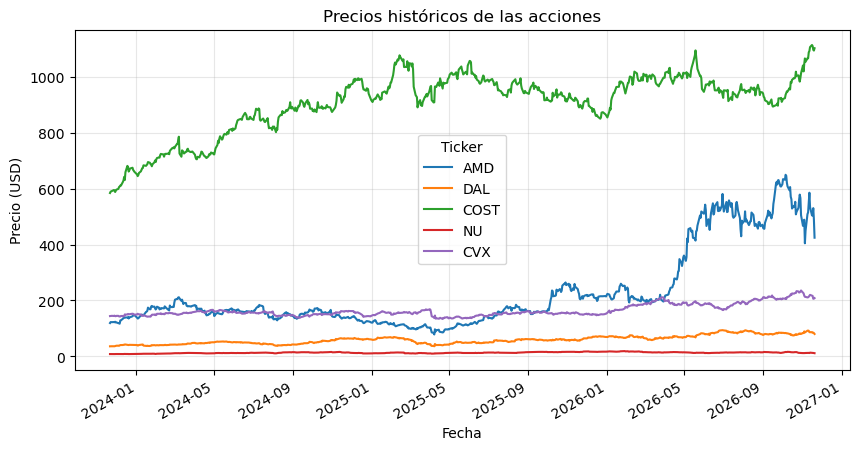

In [ ]:
prices.plot(figsize=(10,5))
plt.title("Precios históricos")
plt.xlabel("Fecha")
plt.ylabel("Precio (USD)")
plt.show()

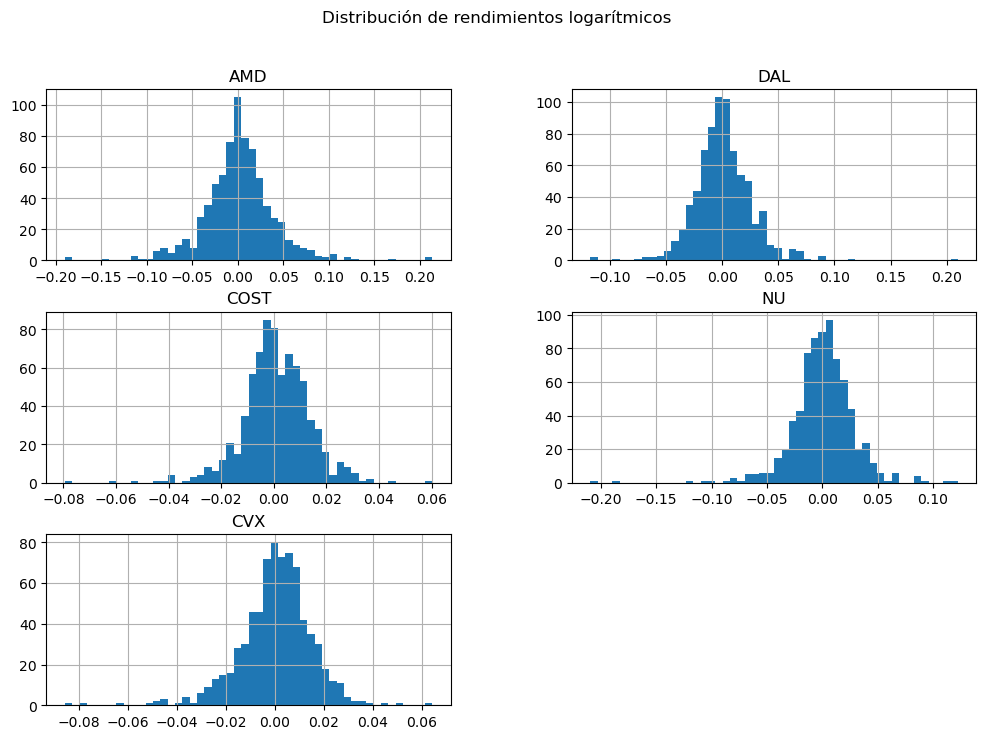

In [ ]:
rets.hist(bins=50, figsize=(10,7))
plt.show()

### 3. Rendimiento, volatilidad y correlación
Como los rendimientos son diarios, multiplicamos la media por 252 y la volatilidad por la raíz de 252 para tener los datos anualizados.

In [ ]:
mu = rets.mean() * 252
vol = rets.std() * np.sqrt(252)

print("Rendimiento anual (%):")
print((mu*100).round(2))
print("Volatilidad anual (%):")
print((vol*100).round(2))

In [ ]:
R = rets.corr()
R.round(3)

**Lo que observamos:** AMD tiene el rendimiento logarítmico promedio más alto (42.56%), pero también la volatilidad más alta (61.60%). COST tiene la menor volatilidad (20.52%). Entonces no necesariamente la acción que más rendimiento ha tenido es la que más nos conviene para reducir el riesgo.

En las gráficas vemos que los precios tienen escalas diferentes. En los histogramas también se nota que los rendimientos de algunas acciones están más dispersos que los de otras. La correlación entre AMD y COST es de 0.018, mientras que entre AMD y DAL es de 0.353. Aunque las empresas sean de diferentes sectores, no podemos considerar que todos sus movimientos sean independientes.

### 4. Covarianza y Cholesky

Calculamos la matriz de covarianzas anualizada y aplicamos Cholesky para tomar en cuenta la relación entre los rendimientos de las cinco acciones.

In [ ]:
Sigma = rets.cov()*252
L = np.linalg.cholesky(Sigma)
print(Sigma)
L

### 5. Monte Carlo

Usamos 10,000 simulaciones y un horizonte de un año. Generamos normales independientes y después las multiplicamos por L para obtener Z. Como Z ya contiene la volatilidad y mu es la media anual de los rendimientos logarítmicos, no volvemos a multiplicar por la volatilidad ni a restar la mitad de la varianza.

In [ ]:
T = 1
M = 10000
V0 = 100000
S0 = prices.iloc[-1].values
w = np.array([0.20, 0.20, 0.20, 0.20, 0.20])

np.random.seed(67)
epsilon = np.random.normal(0, 1, (len(tickers), M))
Z = L @ epsilon
Z.T

array([[ 0.69518924,  0.20855402,  0.07970749,  0.23653894,  0.3725375 ],
       [ 0.08882495, -0.19926   ,  0.19402278,  0.04226138, -0.02273335],
       [-0.68701866,  0.19820559,  0.23593154,  0.17358053, -0.05529084],
       ...,
       [ 0.46251713,  0.03089718, -0.00319522,  1.35982089, -0.50627153],
       [-1.18462586, -0.41408653,  0.06766956,  0.1800906 , -0.15959958],
       [-0.41021943,  0.31689571,  0.4463062 ,  1.05796514,  0.36416182]],
      shape=(10000, 5))

In [ ]:
ST = S0 * np.exp(mu.values*T + np.sqrt(T)*Z.T)
ST = pd.DataFrame(ST, columns=tickers)
ST.head()

,AMD,DAL,COST,NU,CVX
0,1301.782109,128.953448,1476.434475,15.909067,342.263961
1,709.900750,85.767268,1655.238868,13.099992,230.513955
2,326.778170,127.625863,1726.081994,14.938336,223.129855
3,1386.650297,73.996976,1249.480296,18.621552,166.321699
4,590.534531,80.275560,1300.624975,29.574227,228.705297


### 6. Valor final del portafolio
Invertimos 20% en cada acción y usamos acciones fraccionarias para invertir exactamente los $100,000 USD. Al valor final le restamos el capital inicial para obtener las ganancias y pérdidas.

In [ ]:
N = V0*w/S0
print(pd.DataFrame({"Acción": tickers, "Cantidad": N, "Peso": w}))

VT = V0 * np.sum((ST.values / S0) * w, axis=1)
PnL = VT - V0
rend_port = PnL / V0

print(f"Valor final promedio: ${np.mean(VT):,.2f}")
print(f"Ganancia promedio: ${np.mean(PnL):,.2f}")
print("Rendimiento promedio (%):", round(np.mean(rend_port)*100,2))
print("Probabilidad de pérdida (%):", round(np.mean(PnL<0)*100,2))

  Acción     Cantidad  Peso
0    AMD    47.126462   0.2
1    DAL   249.968748   0.2
2   COST    18.146350   0.2
3     NU  1774.622893   0.2
4    CVX    95.983109   0.2
Valor final promedio: $138,446.99
Ganancia promedio: $38,446.99
Rendimiento promedio (%): 38.45
Probabilidad de pérdida (%): 12.41


In [ ]:
plt.hist(VT, bins=50)
plt.axvline(V0, color="black", linestyle="--", label="Capital inicial")
plt.axvline(np.mean(VT), color="red", linestyle="--", label="Media")
plt.title("Valor final del portafolio")
plt.xlabel("Valor final (USD)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

/tmp/ipykernel_787/206704970.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [ ]:
plt.hist(rend_port*100, bins=50)
plt.axvline(0, color="black", linestyle="--")
plt.title("Rendimientos del portafolio")
plt.xlabel("Rendimiento (%)")
plt.ylabel("Frecuencia")
plt.show()

/tmp/ipykernel_787/3199962744.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### 7. VaR y CVaR

Sacamos el percentil 5 de las ganancias y pérdidas. El VaR es ese percentil con signo contrario y el CVaR es la pérdida promedio dentro del 5% de los escenarios más bajos.

In [ ]:
q = np.percentile(PnL, 5)
VaR = -q
CVaR = -np.mean(PnL[PnL <= q])
error_MC = np.std(VT, ddof=1)/np.sqrt(M)

print("VaR 95%:", round(VaR,2))
print("CVaR 95%:", round(CVaR,2))
print("Error estándar:", round(error_MC,2))

VaR 95%: 9716.72
CVaR 95%: 17536.21
Error estándar: 381.48


In [ ]:
plt.hist(PnL, bins=50)
plt.axvline(q, color="red", linestyle="--", label="VaR 95%")
plt.axvline(-CVaR, color="orange", linestyle="--", label="CVaR 95%")
plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Ganancia o pérdida (USD)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

/tmp/ipykernel_787/1475863836.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### 8. Variables antitéticas

Tomamos 5,000 valores de Z y después hacemos lo mismo con -Z para tener 10,000 escenarios. Sacamos el promedio de cada pareja para estimar el valor del portafolio. Para el VaR y CVaR usamos los 10,000 valores individuales porque queremos medir las posibles pérdidas del portafolio, no las pérdidas del promedio de dos escenarios.

In [ ]:
mitad = M//2
Z_ant = Z[:, :mitad]

ST_z = S0*np.exp(mu.values*T + np.sqrt(T)*Z_ant.T)
ST_menosZ = S0*np.exp(mu.values*T - np.sqrt(T)*Z_ant.T)

VT_z = V0*np.sum((ST_z/S0)*w, axis=1)
VT_menosZ = V0*np.sum((ST_menosZ/S0)*w, axis=1)

V_promedio = (VT_z + VT_menosZ)/2
valor_ant = np.mean(V_promedio)
error_ant = np.std(V_promedio, ddof=1)/np.sqrt(mitad)

VT_ant = np.concatenate((VT_z, VT_menosZ))
PnL_ant = VT_ant - V0
q_ant = np.percentile(PnL_ant, 5)
VaR_ant = -q_ant
CVaR_ant = -np.mean(PnL_ant[PnL_ant <= q_ant])

print("Valor esperado:", round(valor_ant,2))
print("Error estándar:", round(error_ant,2))

Valor esperado: 138571.0
Error estándar: 168.58


### 9. Variable de control

Tomamos Y como el valor final del portafolio y X como el precio final de AMD. Escogimos AMD porque forma parte del portafolio y su precio está relacionado con Y. Calculamos EX con la esperanza de la distribución lognormal y después sacamos b para ajustar los valores de Y.

In [ ]:
Y = VT
X = ST["AMD"].values
EX = S0[0]*np.exp(mu.iloc[0]*T + 0.5*vol.iloc[0]**2*T)

x_media = np.mean(X)
y_media = np.mean(Y)

b = np.sum((X-x_media)*(Y-y_media))/np.sum((X-x_media)**2)
Y_control = Y-b*(X-EX)
valor_control = np.mean(Y_control)
error_control = np.std(Y_control, ddof=1)/np.sqrt(M)

print("Sin variable de control:", round(y_media,2))
print("Con variable de control:", round(valor_control,2))
print("Reducción de varianza (%):", round((1-np.var(Y_control,ddof=1)/np.var(Y,ddof=1))*100,2))

Sin variable de control: 138446.99
Con variable de control: 138557.92
Reducción de varianza (%): 70.71


Aquí lo que estamos ajustando es la estimación del valor promedio, no los precios finales del portafolio. Por eso el VaR y CVaR son los mismos del Monte Carlo original. No estamos estimando de nuevo esas dos medidas con la variable de control.

In [ ]:
VaR_control = VaR
CVaR_control = CVaR

### 10. Quasi Monte Carlo (Sobol)

Primero generamos uniformes con Sobol y después los pasamos a una normal con norm.ppf. Usamos cinco dimensiones, una por acción. Como Sobol trabaja mejor con potencias de 2, generamos 16,384 puntos y usamos los primeros 10,000 para comparar con los otros métodos. Al recortar los puntos perdemos parte de las propiedades de balance de la secuencia.

In [ ]:
sobol = qmc.Sobol(d=len(tickers), scramble=True, seed=32)
u = sobol.random_base2(m=14)
u = u[:M]
z = norm.ppf(np.clip(u, 1e-12, 1-1e-12))

Z_sobol = L @ z.T
ST_sobol = S0*np.exp(mu.values*T + np.sqrt(T)*Z_sobol.T)
VT_sobol = V0*np.sum((ST_sobol/S0)*w, axis=1)
PnL_sobol = VT_sobol - V0

valor_sobol = np.mean(VT_sobol)
q_sobol = np.percentile(PnL_sobol,5)
VaR_sobol = -q_sobol
CVaR_sobol = -np.mean(PnL_sobol[PnL_sobol <= q_sobol])

Para el error estándar repetimos Sobol con 10 semillas distintas. Como sus puntos no son independientes, usamos la desviación de los 10 valores estimados para aproximar el error de una corrida de 10,000 escenarios. No dividimos entre la raíz de 10 porque en la tabla estamos reportando una sola corrida, no el promedio de las 10.

In [ ]:
estimaciones = []

for i in range(10):
    sobol = qmc.Sobol(d=len(tickers), scramble=True, seed=i)
    u = sobol.random_base2(m=14)[:M]
    z = norm.ppf(np.clip(u, 1e-12, 1-1e-12))
    Z_rep = L @ z.T
    ST_rep = S0*np.exp(mu.values*T + np.sqrt(T)*Z_rep.T)
    VT_rep = V0*np.sum((ST_rep/S0)*w, axis=1)
    estimaciones.append(np.mean(VT_rep))

error_sobol = np.std(estimaciones, ddof=1)
print("Valor estimado:", round(valor_sobol,2))
print("Error estándar aproximado:", round(error_sobol,2))

Valor estimado: 138578.93
Error estándar aproximado: 11.91


### 11. Comparación de métodos

In [ ]:
tabla = pd.DataFrame({
    "Método": ["Monte Carlo", "Variables antitéticas", "Variable de control", "Quasi Monte Carlo"],
    "Valor estimado": [np.mean(VT), valor_ant, valor_control, valor_sobol],
    "VaR95": [VaR, VaR_ant, VaR_control, VaR_sobol],
    "CVaR95": [CVaR, CVaR_ant, CVaR_control, CVaR_sobol],
    "Error estándar": [error_MC, error_ant, error_control, error_sobol]
})
tabla.round(2)

,Método,Valor estimado,VaR95,CVaR95,Error estándar
0,Monte Carlo,138446.99,9716.72,17536.21,381.48
1,Variables antitéticas,138571.00,9825.26,17377.23,168.58
2,Variable de control,138557.92,9716.72,17536.21,206.47
3,Quasi Monte Carlo,138578.93,9905.16,17226.22,11.91


**Lo que observamos:** los cuatro valores esperados son parecidos porque estamos simulando el mismo portafolio con los mismos parámetros. Con Monte Carlo obtenemos un error estándar de $381.48 USD. Con las antitéticas baja a $168.58 y con la variable de control a $206.47. Sobol tiene el menor error estándar, de aproximadamente $11.91.

Monte Carlo es el más sencillo de aplicar, pero en este caso tiene más variación en la estimación de la media. Con las antitéticas aprovechamos Z y -Z sin aumentar el número de simulaciones, aunque no siempre se reduce la varianza. Con la variable de control necesitamos conocer EX y que X esté relacionada con Y. Con Sobol los puntos están más repartidos, aunque tenemos la limitación de usar 10,000 en vez de una potencia de 2.

Para este portafolio recomendaríamos Sobol para estimar el valor esperado. Que tenga menor error estándar en la media no significa que necesariamente tenga el VaR más preciso.

### 12. Stress testing
Vamos a usar las mismas normales que en el escenario base para comparar qué pasa cuando cambiamos una condición a la vez.

**Escenario 1. Caída general del mercado**
Suponemos una caída adicional de 35% en los precios finales de todas las acciones.

In [ ]:
ST_1 = ST.values*(1-0.35)
VT_1 = V0*np.sum((ST_1/S0)*w, axis=1)
PnL_1 = VT_1-V0

**Escenario 2. Doble volatilidad**
Multiplicamos Z por 2 porque ya contiene la volatilidad de cada acción. Dejamos fija la media logarítmica, por lo que el valor promedio puede subir por la forma exponencial del modelo, aunque el riesgo aumente.

In [ ]:
ST_2 = S0*np.exp(mu.values*T + 2*np.sqrt(T)*Z.T)
VT_2 = V0*np.sum((ST_2/S0)*w, axis=1)
PnL_2 = VT_2-V0

**Escenario 3. Colapso de diversificación**
Ponemos una correlación de 0.99 entre las acciones y dejamos 1 en la diagonal. Volvemos a calcular la covarianza y Cholesky, sin cambiar las volatilidades individuales.

In [ ]:
R_3 = np.ones((len(tickers),len(tickers)))*0.99

for i in range(len(tickers)):
    R_3[i,i] = 1

Sigma_3 = np.zeros((len(tickers),len(tickers)))
for i in range(len(tickers)):
    for j in range(len(tickers)):
        Sigma_3[i,j] = R_3[i,j]*vol.iloc[i]*vol.iloc[j]

L_3 = np.linalg.cholesky(Sigma_3)
Z_3 = L_3 @ epsilon
ST_3 = S0*np.exp(mu.values*T + np.sqrt(T)*Z_3.T)
VT_3 = V0*np.sum((ST_3/S0)*w, axis=1)
PnL_3 = VT_3-V0

In [ ]:
escenarios = {"Base": PnL, "Caída 35%": PnL_1, "Doble volatilidad": PnL_2, "Correlación 0.99": PnL_3}
resumen = []

for nombre, pnl in escenarios.items():
    q = np.percentile(pnl,5)
    resumen.append({"Escenario": nombre, "VaR95": -q, "CVaR95": -np.mean(pnl[pnl <= q])})

tabla_stress = pd.DataFrame(resumen)
tabla_stress.round(2)

,Escenario,VaR95,CVaR95
0,Base,9716.72,17536.21
1,Caída 35%,41315.87,46398.54
2,Doble volatilidad,28755.51,39236.35
3,Correlación 0.99,31472.79,40198.29


In [ ]:
for nombre, pnl in escenarios.items():
    plt.hist(pnl, bins=50, alpha=0.4, label=nombre)

plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Ganancia o pérdida (USD)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

/tmp/ipykernel_787/2197827334.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


**Lo que observamos en los escenarios:** en la caída del 35% toda la distribución se recorre hacia las pérdidas. Al duplicar la volatilidad tenemos resultados más dispersos y el CVaR sube de $17,536.21 a $39,236.35. Al aumentar las correlaciones a 0.99 el CVaR llega a $40,198.29, aunque las volatilidades individuales no cambiaron. En los tres casos aumenta el riesgo, pero con los cambios que planteamos la caída del mercado es el escenario más desfavorable.

### 13. Extra - Optimización de pesos
Planteamos un cliente que busca reducir el riesgo. Usamos como función de costo la varianza anualizada del portafolio, $w^T\Sigma w$. Vamos a probar pesos de 5% en 5%, con un mínimo de 5% y un máximo de 40% por acción, sin ventas en corto. La suma debe ser 100%. Así encontramos la mejor combinación de las que probamos, no necesariamente la mejor entre todos los pesos posibles.

In [ ]:
mejor_costo = w @ Sigma.values @ w
w_opt = w.copy()

for a in range(1,9):
    for b in range(1,9):
        for c in range(1,9):
            for d in range(1,9):
                e = 20-a-b-c-d
                if 1 <= e <= 8:
                    w_prueba = np.array([a,b,c,d,e])/20
                    costo = w_prueba @ Sigma.values @ w_prueba
                    if costo < mejor_costo:
                        mejor_costo = costo
                        w_opt = w_prueba.copy()

pd.DataFrame({"Acción": tickers, "Peso original (%)": w*100, "Peso optimizado (%)": w_opt*100})

,Acción,Peso original (%),Peso optimizado (%)
0,AMD,20.0,5.0
1,DAL,20.0,10.0
2,COST,20.0,40.0
3,NU,20.0,5.0
4,CVX,20.0,40.0


In [ ]:
VT_opt = V0*np.sum((ST.values/S0)*w_opt, axis=1)
PnL_opt = VT_opt-V0
q_opt = np.percentile(PnL_opt,5)
VaR_opt = -q_opt
CVaR_opt = -np.mean(PnL_opt[PnL_opt <= q_opt])

vol_original = np.sqrt(w @ Sigma.values @ w)
vol_opt = np.sqrt(mejor_costo)

tabla_opt = pd.DataFrame({
    "Portafolio": ["Original", "Optimizado"],
    "Valor esperado": [np.mean(VT), np.mean(VT_opt)],
    "Volatilidad histórica (%)": [vol_original*100, vol_opt*100],
    "VaR95": [VaR, VaR_opt],
    "CVaR95": [CVaR, CVaR_opt]
})
tabla_opt.round(2)

,Portafolio,Valor esperado,Volatilidad histórica (%),VaR95,CVaR95
0,Original,138446.99,23.64,9716.72,17536.21
1,Optimizado,126674.16,15.53,4135.24,9968.70


In [ ]:
plt.hist(PnL, bins=50, alpha=0.4, label="Original")
plt.hist(PnL_opt, bins=50, alpha=0.4, label="Optimizado")
plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Ganancia o pérdida (USD)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

/tmp/ipykernel_787/1523637994.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


**Lo que observamos en la optimización:** al probar las combinaciones de pesos encontramos 5% en AMD, 10% en DAL, 40% en COST, 5% en NU y 40% en CVX. La volatilidad histórica baja de 23.64% a 15.53%. El VaR y CVaR también bajan en la simulación, pero el valor esperado es menor. COST y CVX tienen las volatilidades más bajas de las cinco acciones, por eso tienen más peso. Esta combinación es la mejor de las que probamos de 5% en 5%.

### 14. Conclusiones

En este proyecto vimos que no basta con revisar cuánto esperamos ganar en un portafolio. Con los pesos de 20% en cada acción obtuvimos un valor promedio de $138,446.99 USD, pero también hay escenarios en los que perdemos parte del capital. El VaR fue de $9,716.72 y el CVaR de $17,536.21. Es decir, en el 5% de los escenarios más bajos perdemos en promedio $17,536.21.

**¿Invertiríamos en este portafolio?**

Para el cliente que planteamos no escogeríamos el portafolio original. Aunque el rendimiento promedio de 38.45% es alto, también tenemos que considerar las pérdidas que podríamos tener. Preferiríamos el optimizado porque la volatilidad pasa de 23.64% a 15.53% y el CVaR baja a $9,968.70. Aun así, tendríamos que revisar que el cliente esté dispuesto a tener el 80% de su dinero en solo dos acciones. Al reducir el riesgo también estamos dejando de obtener parte del rendimiento esperado, ya que el valor promedio baja a $126,674.16.

**¿Cuál fue el principal factor de riesgo?**

De los tres escenarios que probamos, la caída general del mercado de 35% fue el que más afectó al portafolio. El VaR pasó de $9,716.72 a $41,315.87 y el CVaR a $46,398.54. También vimos que al aumentar las correlaciones a 0.99 el VaR sube a $31,472.79. Entonces repartir el dinero entre empresas de distintos sectores sí ayuda, pero no nos protege completamente cuando todas caen al mismo tiempo.

**¿Qué limitación importante tiene el modelo?**

Estamos usando rendimientos históricos para simular lo que podría pasar durante el siguiente año y suponemos que las medias, volatilidades y correlaciones se mantienen. En la realidad estas pueden cambiar y los rendimientos logarítmicos no siempre se comportan como una normal. Por eso no podemos tomar el 38.45% como un rendimiento que vamos a obtener. Tampoco consideramos dividendos ni costos de transacción.

De los métodos que comparamos, nos quedaríamos con Sobol para estimar el valor esperado porque en este ejercicio fue el que tuvo menor error estándar. Para las pérdidas también revisaríamos los resultados de Monte Carlo tradicional.